In [ ]:
# ============================================================
# Cell 0 — session manifest
# ============================================================
!pip install geopandas pyogrio --quiet

import sys, platform, datetime, hashlib, json, os
from pathlib import Path
import pandas as pd
import numpy as np

print("UTC:", datetime.datetime.now(datetime.UTC).isoformat())
print("Python:", sys.version.split()[0])
print("Platform:", platform.platform())
print("pandas:", pd.__version__, "| numpy:", np.__version__)
try:
    import geopandas as gpd
    print("geopandas:", gpd.__version__)
    import pyogrio
    print("pyogrio:", pyogrio.__version__)
    try:
        import fiona; print("fiona:", fiona.__version__)
    except Exception:
        print("fiona: (not installed — using pyogrio as shapefile reader)")
    try:
        from osgeo import gdal; print("GDAL:", gdal.__version__)
    except Exception:
        print("GDAL: (pyosgeo not installed — fine with pyogrio)")
except Exception as e:
    print("geopandas: NOT AVAILABLE —", e)

print()
print("RECORD THIS IN EVERY REPORT_BACK.md 'Execution environment and versions' FIELD.")

UTC: 2026-11-18T14:16:52.878523+00:00
Python: 3.13.18
Platform: Linux-6.6.159+-x86_64-with-glibc2.39
pandas: 2.2.3 | numpy: 2.4.6
geopandas: 1.2.0
pyogrio: 0.13.0
fiona: (not installed — using pyogrio as shapefile reader)
GDAL: 3.8.4

RECORD THIS IN EVERY REPORT_BACK.md 'Execution environment and versions' FIELD.


In [ ]:
import geopandas as gpd
print("engines available:", gpd.io.file._get_engine if hasattr(gpd.io.file, '_get_engine') else 'n/a')

engines available: n/a


In [ ]:
import pyogrio
print("pyogrio drivers:", list(pyogrio.list_drivers().items())[:5])

pyogrio drivers: [('MEM', 'rw'), ('PCIDSK', 'raw'), ('PDS4', 'raw'), ('VICAR', 'rw'), ('PDF', 'w')]


In [ ]:
import pyogrio
print("pyogrio drivers:", pyogrio.list_drivers())

pyogrio drivers: {'MEM': 'rw', 'PCIDSK': 'raw', 'PDS4': 'raw', 'VICAR': 'rw', 'PDF': 'w', 'MBTiles': 'rw', 'EEDA': 'r', 'OGCAPI': 'r', 'GDALG': 'r', 'ESRI Shapefile': 'raw', 'MapInfo File': 'raw', 'LVBAG': 'r', 'S57': 'rw', 'DGN': 'rw', 'OGR_VRT': 'r', 'CSV': 'raw', 'GML': 'rw', 'GPX': 'rw', 'LIBKML': 'raw', 'KML': 'rw', 'GeoJSON': 'raw', 'GeoJSONSeq': 'raw', 'ESRIJSON': 'r', 'TopoJSON': 'r', 'OGR_GMT': 'rw', 'GPKG': 'raw', 'SQLite': 'raw', 'WAsP': 'rw', 'OpenFileGDB': 'raw', 'DXF': 'rw', 'FlatGeobuf': 'rw', 'GeoRSS': 'rw', 'VFK': 'r', 'PGDUMP': 'w', 'OSM': 'r', 'GPSBabel': 'rw', 'OGR_PDS': 'r', 'WFS': 'r', 'OAPIF': 'r', 'EDIGEO': 'r', 'Idrisi': 'r', 'ODS': 'raw', 'XLSX': 'raw', 'Elasticsearch': 'rw', 'Carto': 'rw', 'AmigoCloud': 'rw', 'SXF': 'r', 'Selafin': 'rw', 'JML': 'rw', 'PLSCENES': 'r', 'CSW': 'r', 'VDV': 'rw', 'MVT': 'rw', 'NGW': 'rw', 'MapML': 'rw', 'GTFS': 'r', 'PMTiles': 'rw', 'JSONFG': 'rw', 'MiraMonVector': 'rw', 'ADBC': 'r', 'AVCBin': 'r', 'AVCE00': 'r', 'AIVector': 'r', 

In [ ]:
import geopandas as gpd, pyogrio
print("gpd default engine:", gpd.options.io_engine)
print("shapefile driver present:", "ESRI Shapefile" in pyogrio.list_drivers())

gpd default engine: None
shapefile driver present: True


In [ ]:
# ============================================================
# Cell 1 — mount Drive
# ============================================================
from google.colab import drive
drive.mount('/content/drive')

from pathlib import Path
DRIVE_ROOT = Path('/content/drive/MyDrive')
print("Drive mounted. Top-level:")
for p in sorted(DRIVE_ROOT.iterdir())[:20]:
    print("  ", p.name)

Mounted at /content/drive
Drive mounted. Top-level:
   Colab Notebooks
   Smart_Traffic_Density_Detector
   The Waste-to-Wealth Blueprint.gdoc
   mplad-dvc-artifacts
   mplad-dvc-storage


In [ ]:
# ============================================================
# Cell 2 — pin BASE_DIR to mplad-dvc-storage and verify layout
# ============================================================
from pathlib import Path

BASE_DIR = Path('/content/drive/MyDrive/mplad-dvc-storage')
assert BASE_DIR.exists(), f"Folder not found: {BASE_DIR}"

EXPECTED = [
    "PMGSY_Master_Dataset_Combined(1).csv",
    "pmgsy_stream_b_p_unique.csv",
    "pmgsy_stream_b_l_unique.csv",
    "csv_audit.json",
    "Bihar_PMGSY-III.shp", "Bihar_PMGSY-III.shx", "Bihar_PMGSY-III.dbf", "Bihar_PMGSY-III.prj",
    "UP_PMGSY-III.shp",    "UP_PMGSY-III.shx",    "UP_PMGSY-III.dbf",    "UP_PMGSY-III.prj",
    "MP_PMGSY-III.shp",    "MP_PMGSY-III.shx",    "MP_PMGSY-III.dbf",    "MP_PMGSY-III.prj",
]

print(f"BASE_DIR = {BASE_DIR}\n")
missing = []
for name in EXPECTED:
    p = BASE_DIR / name
    if p.exists():
        print(f"OK        {name:45s}  {p.stat().st_size:>10d} bytes")
    else:
        print(f"MISSING   {name}")
        missing.append(name)

if missing:
    print(f"\n{len(missing)} expected files missing.")
    print("If they live in a subfolder, set BASE_DIR to that subfolder and rerun.")
    # Helpful diagnostic — show what IS present
    print("\nFull listing of BASE_DIR:")
    for p in sorted(BASE_DIR.iterdir()):
        print(f"  {'DIR ' if p.is_dir() else 'FILE'}  {p.name}")
else:
    print("\nAll expected files present.")

BASE_DIR = /content/drive/MyDrive/mplad-dvc-storage

OK        PMGSY_Master_Dataset_Combined(1).csv               910937 bytes
OK        pmgsy_stream_b_p_unique.csv                        806709 bytes
OK        pmgsy_stream_b_l_unique.csv                        195198 bytes
MISSING   csv_audit.json
OK        Bihar_PMGSY-III.shp                               3809620 bytes
OK        Bihar_PMGSY-III.shx                                 11908 bytes
OK        Bihar_PMGSY-III.dbf                                432885 bytes
OK        Bihar_PMGSY-III.prj                                   143 bytes
OK        UP_PMGSY-III.shp                                  7643628 bytes
OK        UP_PMGSY-III.shx                                    22156 bytes
OK        UP_PMGSY-III.dbf                                   700695 bytes
OK        UP_PMGSY-III.prj                                      143 bytes
OK        MP_PMGSY-III.shp                                  4190380 bytes
OK        MP_PMGSY-III.shx        

In [ ]:
# ============================================================
# Cell 3 — integrity gate (must pass before any analysis)
# ============================================================
import hashlib, json

def sha256_of(p, chunk=1 << 20):
    h = hashlib.sha256()
    with open(p, 'rb') as f:
        for blk in iter(lambda: f.read(chunk), b''):
            h.update(blk)
    return h.hexdigest()

audit = json.loads((BASE_DIR / "csv_audit.json").read_text())

verify_results = []
for name, meta in audit.items():
    if name == "cross_checks":
        continue
    p = BASE_DIR / name
    if not p.exists():
        verify_results.append({"file": name, "ok": False, "reason": "missing"})
        print(f"MISSING  {name}")
        continue
    actual = sha256_of(p)
    expected = meta["sha256"]
    ok = (actual == expected)
    verify_results.append({"file": name, "ok": ok,
                           "expected": expected, "actual": actual})
    print(f"{'PASS' if ok else 'FAIL'}  {name}  expected={expected[:16]}  actual={actual[:16]}")

assert all(r["ok"] for r in verify_results), (
    "STOP. One or more CSV SHA-256 values do not match csv_audit.json. "
    "Do NOT proceed — you are not analysing the audited files."
)
print("\nAll CSVs match the audited SHA-256 values.")

PASS  PMGSY_Master_Dataset_Combined(1).csv  expected=773a799b4ada7a95  actual=773a799b4ada7a95
PASS  pmgsy_stream_b_p_unique.csv  expected=1c577758bfae2468  actual=1c577758bfae2468
PASS  pmgsy_stream_b_l_unique.csv  expected=50bd95061a239b98  actual=50bd95061a239b98

All CSVs match the audited SHA-256 values.


In [ ]:
# ============================================================
# Cell 4 — INV-01 raw geospatial inventory + CSV reconciliation
# ============================================================
import hashlib, json
from pathlib import Path
import pandas as pd

STATES = {
    "Bihar":          "Bihar_PMGSY-III",
    "Uttar Pradesh":  "UP_PMGSY-III",
    "Madhya Pradesh": "MP_PMGSY-III",
}

shp_presence = {}
for state, stem in STATES.items():
    parts = {ext: (BASE_DIR / f"{stem}{ext}").exists()
             for ext in (".shp", ".shx", ".dbf", ".prj")}
    shp_presence[state] = (all(parts.values()), parts)
    print(f"{state:16s} {parts}  -> {'FULL' if all(parts.values()) else 'INCOMPLETE'}")

have_shapefiles = all(v[0] for v in shp_presence.values())
print(f"\nShapefiles fully present? {have_shapefiles}")

master = pd.read_csv(BASE_DIR / "PMGSY_Master_Dataset_Combined(1).csv",
                     dtype=str, keep_default_na=False)
p_df   = pd.read_csv(BASE_DIR / "pmgsy_stream_b_p_unique.csv",
                     dtype=str, keep_default_na=False)
l_df   = pd.read_csv(BASE_DIR / "pmgsy_stream_b_l_unique.csv",
                     dtype=str, keep_default_na=False)

def check(label, expected, actual):
    ok = (expected == actual)
    print(f"{'PASS' if ok else 'FAIL'}  {label}:  expected={expected}  actual={actual}")
    return ok

print("\n--- Master CSV reproduction ---")
check("rows",                  8868, len(master))
check("exact row duplicates",  3001, int(master.duplicated().sum()))
check("unique MRL_ID",         5867, master["MRL_ID"].nunique())
check("P count",               7323, int((master["PROPOSAL_T"] == "P").sum()))
check("L count",               1545, int((master["PROPOSAL_T"] == "L").sum()))

print("\n--- P/L split reproduction ---")
check("P rows",                7670, len(p_df))
check("P exact row duplicates",   0, int(p_df.duplicated().sum()))
check("L rows",                1964, len(l_df))
check("L exact row duplicates",   0, int(l_df.duplicated().sum()))
check("P+L shared MRL_ID",        0, len(set(p_df["MRL_ID"]) & set(l_df["MRL_ID"])))
check("P+L total rows",        9634, len(p_df) + len(l_df))

print("\n--- Master vs split relationship ---")
bihar_up_mp_p = int((p_df["SOURCE_STATE"] == "Bihar_UP_MP").sum())
bihar_up_mp_l = int((l_df["SOURCE_STATE"] == "Bihar_UP_MP").sum())
check("master unique == Bihar_UP_MP in P+L",
      master["MRL_ID"].nunique(),
      bihar_up_mp_p + bihar_up_mp_l)
print("\nINTERPRETATION:")
print("  Master CSV is the 3-state subset (Bihar, MP, UP) with attribute-duplicate surplus.")
print(f"  Split files add {p_df['SOURCE_STATE'].nunique()} source groups "
      f"({sorted(set(p_df['SOURCE_STATE']) | set(l_df['SOURCE_STATE']))}).")

inv01_raw = []
if have_shapefiles:
    import geopandas as gpd
    print("\n--- Shapefile raw inventory ---")
    for state, stem in STATES.items():
        for ext in (".shp", ".shx", ".dbf", ".prj"):
            p = BASE_DIR / f"{stem}{ext}"
            inv01_raw.append({
                "state": state, "part": ext, "path": str(p),
                "bytes": p.stat().st_size, "sha256": sha256_of(p),
            })
        gdf = gpd.read_file(BASE_DIR / f"{stem}.shp")
        print(f"{state}: features={len(gdf)} "
              f"crs={gdf.crs} "
              f"geom_types={gdf.geom_type.value_counts().to_dict()} "
              f"cols={list(gdf.columns)}")
        inv01_raw.append({
            "state": state, "part": "FEATURES",
            "features": len(gdf), "crs": str(gdf.crs),
            "geom_types": str(gdf.geom_type.value_counts().to_dict()),
        })

inv01_dir = BASE_DIR / "outputs"
inv01_dir.mkdir(exist_ok=True)
pd.DataFrame(inv01_raw).to_csv(inv01_dir / "INV01_raw_inventory.csv", index=False)
print(f"\nSaved {inv01_dir / 'INV01_raw_inventory.csv'}")

print("\nINV-01 DISPOSITION:",
      "PASS" if have_shapefiles else "CONDITIONAL (CSV-only; raw lineage BLOCKED)")

Bihar            {'.shp': True, '.shx': True, '.dbf': True, '.prj': True}  -> FULL
Uttar Pradesh    {'.shp': True, '.shx': True, '.dbf': True, '.prj': True}  -> FULL
Madhya Pradesh   {'.shp': True, '.shx': True, '.dbf': True, '.prj': True}  -> FULL

Shapefiles fully present? True

--- Master CSV reproduction ---
PASS  rows:  expected=8868  actual=8868
PASS  exact row duplicates:  expected=3001  actual=3001
PASS  unique MRL_ID:  expected=5867  actual=5867
PASS  P count:  expected=7323  actual=7323
PASS  L count:  expected=1545  actual=1545

--- P/L split reproduction ---
PASS  P rows:  expected=7670  actual=7670
PASS  P exact row duplicates:  expected=0  actual=0
PASS  L rows:  expected=1964  actual=1964
PASS  L exact row duplicates:  expected=0  actual=0
PASS  P+L shared MRL_ID:  expected=0  actual=0
PASS  P+L total rows:  expected=9634  actual=9634

--- Master vs split relationship ---
PASS  master unique == Bihar_UP_MP in P+L:  expected=5867  actual=5867

INTERPRETATION:
  Master CSV

In [ ]:
# ============================================================
# Cell 5 — INV-02 duplicate characterization
# ============================================================
import pandas as pd, hashlib, numpy as np

master = pd.read_csv(BASE_DIR / "PMGSY_Master_Dataset_Combined(1).csv",
                     dtype=str, keep_default_na=False)
p_df   = pd.read_csv(BASE_DIR / "pmgsy_stream_b_p_unique.csv",
                     dtype=str, keep_default_na=False)
l_df   = pd.read_csv(BASE_DIR / "pmgsy_stream_b_l_unique.csv",
                     dtype=str, keep_default_na=False)

print("=== Attribute duplicate groups in master CSV ===")
grp = master.groupby("MRL_ID").size()
print(f"IDs with multiplicity 1:  {(grp == 1).sum()}")
print(f"IDs with multiplicity >1: {(grp > 1).sum()}")
print(f"Total rows in multi-groups: {grp[grp > 1].sum()}")

candidate_keys = [
    ["MRL_ID"],
    ["STATE_ID", "DISTRICT_I", "WORK_NAME"],
    ["STATE_NAME", "DISTRICT_I", "WORK_NAME"],
    ["LGD_STATE", "LGD_DISTRI", "BLOCK_ID", "WORK_NAME"],
    ["STATE_ID", "DISTRICT_I", "WORK_NAME", "PROPOSED_L", "IMS_YEAR", "IMS_BATCH"],
]
print("\n=== Duplicate counts per candidate key (informational only) ===")
for keys in candidate_keys:
    print(f"  {keys}: {int(master.duplicated(subset=keys).sum())}")

inv02_rows = []
if have_shapefiles:
    import geopandas as gpd
    print("\n=== Geometry-aware duplicate categorization ===")
    for state, stem in STATES.items():
        gdf = gpd.read_file(BASE_DIR / f"{stem}.shp").to_crs("EPSG:4326")

        def geom_hash(g):
            if g is None or g.is_empty:
                return "EMPTY"
            return hashlib.sha256(g.wkb_hex.encode()).hexdigest()[:16]

        gdf.columns = [c.upper() for c in gdf.columns]
        gdf = gdf.set_geometry("GEOMETRY")               # <-- fixed: re-attach after rename
        gdf["_geom_h"] = gdf.geometry.apply(geom_hash)

        attr_cols = [c for c in gdf.columns
                     if c not in ("GEOMETRY", "_GEOM_H", "STATE_NAME")]

        key_all_attrs = gdf.duplicated(subset=attr_cols, keep=False)
        subgroups = (gdf[key_all_attrs]
                     .groupby(attr_cols, dropna=False)
                     .agg(n=("_geom_h", "size"),
                          distinct_geom=("_geom_h", "nunique"))
                     .reset_index())
        exact_same_geom = int((subgroups["distinct_geom"] == 1).sum())
        exact_diff_geom = int((subgroups["distinct_geom"] > 1).sum())

        by_mrl = gdf.groupby("MRL_ID").agg(
            n=("_geom_h", "size"), distinct_geom=("_geom_h", "nunique")
        )
        same_id_same_geom = int(((by_mrl["n"] > 1) & (by_mrl["distinct_geom"] == 1)).sum())
        same_id_diff_geom = int(((by_mrl["n"] > 1) & (by_mrl["distinct_geom"] > 1)).sum())

        print(f"\n{state}:")
        print(f"  features                     = {len(gdf)}")
        print(f"  attribute groups (all cols)  = {len(subgroups)}")
        print(f"  └ same geometry              = {exact_same_geom}")
        print(f"  └ distinct geometry          = {exact_diff_geom}")
        print(f"  MRL_ID groups (n>1)          = {(by_mrl['n'] > 1).sum()}")
        print(f"  └ same geometry              = {same_id_same_geom}")
        print(f"  └ distinct geometry          = {same_id_diff_geom}")

        inv02_rows.append({
            "state": state, "features": len(gdf),
            "attr_groups": len(subgroups),
            "attr_groups_same_geom": exact_same_geom,
            "attr_groups_diff_geom": exact_diff_geom,
            "mrl_groups_dup": int((by_mrl["n"] > 1).sum()),
            "mrl_groups_same_geom": same_id_same_geom,
            "mrl_groups_diff_geom": same_id_diff_geom,
        })

pd.DataFrame(inv02_rows).to_csv(BASE_DIR / "outputs" / "INV02_geometry_categories.csv", index=False)
print(f"\nSaved {BASE_DIR / 'outputs' / 'INV02_geometry_categories.csv'}")

print("\nINV-02 DISPOSITION:",
      "PASS (geometry-aware)" if have_shapefiles
      else "CONDITIONAL (attribute-only; geometry BLOCKED)")
print("No deletion rule adopted. All groups reported, none removed.")

=== Attribute duplicate groups in master CSV ===
IDs with multiplicity 1:  5026
IDs with multiplicity >1: 841
Total rows in multi-groups: 3842

=== Duplicate counts per candidate key (informational only) ===
  ['MRL_ID']: 3001
  ['STATE_ID', 'DISTRICT_I', 'WORK_NAME']: 4513
  ['STATE_NAME', 'DISTRICT_I', 'WORK_NAME']: 4513
  ['LGD_STATE', 'LGD_DISTRI', 'BLOCK_ID', 'WORK_NAME']: 4506
  ['STATE_ID', 'DISTRICT_I', 'WORK_NAME', 'PROPOSED_L', 'IMS_YEAR', 'IMS_BATCH']: 3639

=== Geometry-aware duplicate categorization ===

Bihar:
  features                     = 1476
  attribute groups (all cols)  = 0
  └ same geometry              = 0
  └ distinct geometry          = 0
  MRL_ID groups (n>1)          = 37
  └ same geometry              = 0
  └ distinct geometry          = 37

Uttar Pradesh:
  features                     = 2757
  attribute groups (all cols)  = 1
  └ same geometry              = 1
  └ distinct geometry          = 0
  MRL_ID groups (n>1)          = 143
  └ same geometry       

In [ ]:
# ============================================================
# Cell 6 — INV-03 field dictionary, cohort cube, quality profile
# ============================================================
import pandas as pd, numpy as np

master = pd.read_csv(BASE_DIR / "PMGSY_Master_Dataset_Combined(1).csv",
                     dtype=str, keep_default_na=False)
p_df   = pd.read_csv(BASE_DIR / "pmgsy_stream_b_p_unique.csv",
                     dtype=str, keep_default_na=False)
l_df   = pd.read_csv(BASE_DIR / "pmgsy_stream_b_l_unique.csv",
                     dtype=str, keep_default_na=False)

field_dict = [
    ("MRL_ID",     "string",  "UNVERIFIED", "MRL segment ID; label not key (INV-02)"),
    ("STATE_ID",   "string",  "IDENTIFIER", "State code"),
    ("STATE_NAME", "string",  "IDENTIFIER", "State name tagged during merge"),
    ("DISTRICT_I", "string",  "IDENTIFIER", "District code (source-specific)"),
    ("LGD_STATE",  "string",  "IDENTIFIER", "LGD state code"),
    ("LGD_DISTRI", "string",  "IDENTIFIER", "LGD district code"),
    ("BLOCK_ID",   "string",  "IDENTIFIER", "Block code"),
    ("CN_CODE",    "string",  "UNVERIFIED", "Present only for L rows in master; meaning undocumented"),
    ("PROPOSED_L", "float",   "MEASUREMENT","Proposed length; units assumed km UNVERIFIED; L all zero"),
    ("WORK_NAME",  "string",  "CONTEXT",    "Proposed work description"),
    ("IMS_YEAR",   "int",     "TEMPORAL",   "IMS edition year; L has 2026 row in split"),
    ("IMS_BATCH",  "int",     "TEMPORAL",   "IMS batch (1/2/3 depending on cohort)"),
    ("PROPOSAL_T", "char",    "CONTEXT",    "P=road, L=bridge (prior vocabulary; UNVERIFIED)"),
    ("SOURCE_STATE","string", "PROVENANCE", "Source group in split files; not identical to STATE_NAME"),
]
fd = pd.DataFrame(field_dict, columns=["field","dtype","category","notes"])
print(fd.to_string(index=False))
fd.to_csv(BASE_DIR / "outputs" / "INV03_field_dictionary.csv", index=False)

print("\n=== Missingness ===")
for name, df in [("master", master), ("P", p_df), ("L", l_df)]:
    miss = (df.replace("", pd.NA).isna().mean() * 100).round(2)
    miss = miss[miss > 0]
    print(f"\n{name}:")
    print(miss.to_string() if len(miss) else "  no missing values")

MIN_CELL = 5
def cube(df, cohort_label):
    df = df.copy()
    df["_len"] = pd.to_numeric(df["PROPOSED_L"], errors="coerce")
    c = (df.groupby(["STATE_ID","IMS_YEAR","IMS_BATCH"])
           .agg(n=("MRL_ID","size"),
                sum_len=("_len","sum"),
                mean_len=("_len","mean"),
                median_len=("_len","median"),
                p95_len=("_len", lambda s: s.quantile(0.95)),
                n_zero_len=("_len", lambda s: int((s == 0).sum())))
           .reset_index())
    c["cohort"] = cohort_label
    c["interpretable"] = c["n"] >= MIN_CELL
    return c

cube_all = pd.concat([cube(p_df, "P"), cube(l_df, "L")], ignore_index=True)
cube_all.to_csv(BASE_DIR / "outputs" / "INV03_cohort_cube.csv", index=False)

print("\n=== Cells below MIN_CELL=5 (report only, do not interpret) ===")
small = cube_all[~cube_all["interpretable"]]
print(f"{len(small)} / {len(cube_all)} cells below threshold")
print(small.head(20).to_string(index=False))

p_len = pd.to_numeric(p_df["PROPOSED_L"], errors="coerce").dropna()
print(f"\n=== P PROPOSED_L heaping (descriptive) ===")
print(f"n={len(p_len)}  mean={p_len.mean():.4f}  median={p_len.median():.4f}")
for q in (1.0, 0.5, 0.25, 0.1):
    share = float(np.isclose(p_len % q, 0, atol=1e-9).mean())
    print(f"  share on multiples of {q}: {share:.3f}")
print("NOTE: heaping reported; does not establish measurement intent.")

print("\nINV-03 DISPOSITION: PASS")

       field  dtype    category                                                    notes
      MRL_ID string  UNVERIFIED                   MRL segment ID; label not key (INV-02)
    STATE_ID string  IDENTIFIER                                               State code
  STATE_NAME string  IDENTIFIER                           State name tagged during merge
  DISTRICT_I string  IDENTIFIER                          District code (source-specific)
   LGD_STATE string  IDENTIFIER                                           LGD state code
  LGD_DISTRI string  IDENTIFIER                                        LGD district code
    BLOCK_ID string  IDENTIFIER                                               Block code
     CN_CODE string  UNVERIFIED  Present only for L rows in master; meaning undocumented
  PROPOSED_L  float MEASUREMENT Proposed length; units assumed km UNVERIFIED; L all zero
   WORK_NAME string     CONTEXT                                Proposed work description
    IMS_YEAR    int  

In [ ]:
# ============================================================
# Cell 7 — INV-04 descriptive cross-source comparison
# ============================================================
import pandas as pd

p_df = pd.read_csv(BASE_DIR / "pmgsy_stream_b_p_unique.csv",
                   dtype=str, keep_default_na=False)
p_df["_len"] = pd.to_numeric(p_df["PROPOSED_L"], errors="coerce")
summary = (p_df.groupby("SOURCE_STATE")
                .agg(n=("MRL_ID","size"),
                     mean_len=("_len","mean"),
                     median_len=("_len","median"),
                     p95_len=("_len", lambda s: s.quantile(0.95)),
                     min_year=("IMS_YEAR", lambda s: int(pd.to_numeric(s).min())),
                     max_year=("IMS_YEAR", lambda s: int(pd.to_numeric(s).max())))
                .reset_index().sort_values("n", ascending=False))
print("=== P: descriptive by SOURCE_STATE ===")
print(summary.to_string(index=False))
summary.to_csv(BASE_DIR / "outputs" / "INV04_P_by_source.csv", index=False)

l_df = pd.read_csv(BASE_DIR / "pmgsy_stream_b_l_unique.csv",
                   dtype=str, keep_default_na=False)
l_summary = (l_df.groupby("SOURCE_STATE")
                  .agg(n=("MRL_ID","size"),
                       min_year=("IMS_YEAR", lambda s: int(pd.to_numeric(s).min())),
                       max_year=("IMS_YEAR", lambda s: int(pd.to_numeric(s).max())))
                  .reset_index())
print("\n=== L: descriptive by SOURCE_STATE ===")
print(l_summary.to_string(index=False))
l_summary.to_csv(BASE_DIR / "outputs" / "INV04_L_by_source.csv", index=False)

print("\nNOTE: sample sizes 40..4361. Report comparisons with n values.")
print("      No AUC, no classifier, no model was run in this cell.")
print("\nINV-04 DISPOSITION: CONDITIONAL (descriptive only)")

=== P: descriptive by SOURCE_STATE ===
SOURCE_STATE    n  mean_len  median_len  p95_len  min_year  max_year
 Bihar_UP_MP 4361  8.575791         7.1  17.0000      2019      2024
      Odisha 1400  6.669103         6.0  12.8019      2020      2021
 Maharashtra  992  6.455825         5.8  11.8225      2020      2024
   Rajasthan  917  9.418034         8.0  19.2400      2019      2024

=== L: descriptive by SOURCE_STATE ===
SOURCE_STATE    n  min_year  max_year
 Bihar_UP_MP 1506      2019      2024
 Maharashtra  274      2023      2026
      Odisha  144      2020      2022
   Rajasthan   40      2020      2022

NOTE: sample sizes 40..4361. Report comparisons with n values.
      No AUC, no classifier, no model was run in this cell.

INV-04 DISPOSITION: CONDITIONAL (descriptive only)


In [ ]:
# ============================================================
# Cell 8 — INV-05 feature eligibility gate
# ============================================================
import pandas as pd

p_df = pd.read_csv(BASE_DIR / "pmgsy_stream_b_p_unique.csv",
                   dtype=str, keep_default_na=False)
l_df = pd.read_csv(BASE_DIR / "pmgsy_stream_b_l_unique.csv",
                   dtype=str, keep_default_na=False)

def classify(df, name):
    rows = []
    for c in df.columns:
        s = df[c]; nunique = s.nunique(dropna=False)
        if nunique <= 1:
            cat = "CONSTANT_OR_MISSING"
        elif c in {"MRL_ID","BLOCK_ID","CN_CODE","LGD_STATE","LGD_DISTRI",
                   "STATE_ID","DISTRICT_I","IMS_YEAR","IMS_BATCH",
                   "STATE_NAME","SOURCE_STATE"}:
            cat = "IDENTIFIER_OR_STRATIFIER"
        elif c in {"PROPOSAL_T","WORK_NAME"}:
            cat = "CONTEXT_OR_STRATIFICATION"
        elif c == "PROPOSED_L":
            cat = ("MEASUREMENT"
                   if pd.to_numeric(s, errors="coerce").nunique() > 1
                   else "CONSTANT_OR_MISSING")
        else:
            cat = "UNVERIFIED"
        rows.append({"cohort": name, "field": c,
                     "n_unique": nunique, "category": cat})
    return rows

elig = pd.DataFrame(classify(p_df, "P") + classify(l_df, "L"))
elig.to_csv(BASE_DIR / "outputs" / "INV05_feature_eligibility.csv", index=False)
print(elig.to_string(index=False))

n_num_p = int(((elig["cohort"]=="P") & (elig["category"]=="MEASUREMENT")).sum())
n_num_l = int(((elig["cohort"]=="L") & (elig["category"]=="MEASUREMENT")).sum())
print(f"\n=== Gate ===\nP numeric MEASUREMENT columns: {n_num_p}\nL numeric MEASUREMENT columns: {n_num_l}")
if n_num_p < 2:
    print("P: gate FAILS (>1 independent MEASUREMENT required).")
    print("   -> ML on P BLOCKED pending further feature derivation from INV-02/03.")
if n_num_l < 2:
    print("L: gate FAILS. -> ML on L BLOCKED (PROPOSED_L constant, CN_CODE fully missing).")
print("\nR1 deliverable under these gates: descriptive data-quality observatory, not anomaly ranking.")
print("\nINV-05 DISPOSITION: CONDITIONAL — ML blocked; descriptive candidates only")

cohort        field  n_unique                  category
     P     BLOCK_ID      2340  IDENTIFIER_OR_STRATIFIER
     P      CN_CODE      7670  IDENTIFIER_OR_STRATIFIER
     P   DISTRICT_I       273  IDENTIFIER_OR_STRATIFIER
     P    IMS_BATCH         3  IDENTIFIER_OR_STRATIFIER
     P     IMS_YEAR         6  IDENTIFIER_OR_STRATIFIER
     P   LGD_DISTRI       273  IDENTIFIER_OR_STRATIFIER
     P    LGD_STATE         6  IDENTIFIER_OR_STRATIFIER
     P       MRL_ID      7670  IDENTIFIER_OR_STRATIFIER
     P   PROPOSAL_T         1       CONSTANT_OR_MISSING
     P   PROPOSED_L      1922               MEASUREMENT
     P     STATE_ID         6  IDENTIFIER_OR_STRATIFIER
     P    WORK_NAME      7663 CONTEXT_OR_STRATIFICATION
     P SOURCE_STATE         4  IDENTIFIER_OR_STRATIFIER
     L     BLOCK_ID       659  IDENTIFIER_OR_STRATIFIER
     L      CN_CODE         1       CONSTANT_OR_MISSING
     L   DISTRICT_I       153  IDENTIFIER_OR_STRATIFIER
     L    IMS_BATCH         3  IDENTIFIER_OR_STR

In [ ]:
# ============================================================
# Cell 9 — copy outputs to timestamped folder + file manifest
# ============================================================
import datetime, shutil

stamp = datetime.datetime.now(datetime.UTC).strftime("%Y-%m-%dT%H%MZ")
out_dir = BASE_DIR / f"outputs_{stamp}"
out_dir.mkdir(exist_ok=True)

for f in (BASE_DIR / "outputs").glob("*"):
    shutil.copy2(f, out_dir / f.name)

print(f"Outputs copied to: {out_dir}\n")
for f in sorted(out_dir.iterdir()):
    print(f"  {f.name:45s}  {f.stat().st_size:>10d} bytes")

Outputs copied to: /content/drive/MyDrive/mplad-dvc-storage/outputs_2026-11-18T1640Z

  INV01_raw_inventory.csv                              2062 bytes
  INV02_geometry_categories.csv                         224 bytes
  INV03_cohort_cube.csv                                3097 bytes
  INV03_field_dictionary.csv                            884 bytes
  INV04_L_by_source.csv                                 130 bytes
  INV04_P_by_source.csv                                 310 bytes
  INV05_feature_eligibility.csv                        1043 bytes


In [ ]:
# ============================================================
# Cell 10 — ADD-01: Complete raw .dbf schema & field-omission audit
# ============================================================
import geopandas as gpd
import pyogrio
import pandas as pd
import numpy as np

dbf_audit_rows = []
raw_frames = {}

for state, stem in STATES.items():
    shp_path = BASE_DIR / f"{stem}.shp"
    cpg_path = BASE_DIR / f"{stem}.cpg"
    info = pyogrio.read_info(shp_path)
    gdf = gpd.read_file(shp_path)
    gdf["_source_state_file"] = state
    gdf["_source_row_idx"] = np.arange(len(gdf))
    raw_frames[state] = gdf

    print(f"=== {state} ({stem}.dbf) ===")
    print(f"  .cpg sidecar present : {cpg_path.exists()} | pyogrio encoding: {info.get('encoding')}")
    print(f"  Total raw columns    : {len(gdf.columns) - 3} (+ geometry)")

    for col in [c for c in gdf.columns if c not in ("geometry", "_source_state_file", "_source_row_idx")]:
        s = gdf[col]
        num_s = pd.to_numeric(s, errors="coerce")
        dbf_audit_rows.append({
            "state": state,
            "raw_col": col,
            "raw_dtype": str(s.dtype),
            "n_rows": len(s),
            "n_non_null": int(s.notna().sum()),
            "n_unique": int(s.nunique(dropna=True)),
            "numeric_parseable_share": round(float(num_s.notna().mean()), 4),
            "numeric_nunique": int(num_s.nunique(dropna=True)),
            "in_master_csv": col.upper() in {c.upper() for c in master.columns},
            "sample_values": str(list(s.dropna().unique()[:3])),
        })

dbf_audit_df = pd.DataFrame(dbf_audit_rows)
print("\n=== Columns in raw .dbf NOT in master CSV ===")
omitted = dbf_audit_df[~dbf_audit_df["in_master_csv"]]
print(omitted.to_string(index=False) if len(omitted) else "  NONE — every raw .dbf column is already present in master CSV.")

print("\n=== Full raw .dbf column audit ===")
print(dbf_audit_df[["state", "raw_col", "raw_dtype", "n_unique", "numeric_parseable_share", "numeric_nunique", "in_master_csv"]].to_string(index=False))

dbf_audit_df.to_csv(BASE_DIR / "outputs" / "ADD01_raw_dbf_schema_audit.csv", index=False)

=== Bihar (Bihar_PMGSY-III.dbf) ===
  .cpg sidecar present : False | pyogrio encoding: UTF-8
  Total raw columns    : 12 (+ geometry)
=== Uttar Pradesh (UP_PMGSY-III.dbf) ===
  .cpg sidecar present : False | pyogrio encoding: UTF-8
  Total raw columns    : 12 (+ geometry)
=== Madhya Pradesh (MP_PMGSY-III.dbf) ===
  .cpg sidecar present : False | pyogrio encoding: UTF-8
  Total raw columns    : 12 (+ geometry)

=== Columns in raw .dbf NOT in master CSV ===
  NONE — every raw .dbf column is already present in master CSV.

=== Full raw .dbf column audit ===
         state    raw_col raw_dtype  n_unique  numeric_parseable_share  numeric_nunique  in_master_csv
         Bihar     MRL_ID     int64      1433                   1.0000             1433           True
         Bihar   STATE_ID     int64         1                   1.0000                1           True
         Bihar DISTRICT_I     int64        38                   1.0000               38           True
         Bihar  LGD_STATE  

In [ ]:
# ============================================================
# Cell 11 — ADD-02: Feature-level shapefile-to-master reconstruction
# ============================================================
import hashlib

raw_all = pd.concat(list(raw_frames.values()), ignore_index=True)
raw_all["STATE_NAME_TAG"] = raw_all["_source_state_file"]

# Geometry fingerprint per raw feature
def wkb_fp(g):
    if g is None or g.is_empty:
        return "EMPTY"
    return hashlib.sha256(g.wkb_hex.encode()).hexdigest()[:16]

raw_all["_geom_fp"] = raw_all.geometry.apply(wkb_fp)

# Normalize raw attributes to match master CSV serialization
shared_cols = [c for c in master.columns if c.upper() in {rc.upper() for rc in raw_all.columns} or c == "STATE_NAME"]
raw_norm = pd.DataFrame(index=raw_all.index)
raw_upper_map = {rc.upper(): rc for rc in raw_all.columns}

for col in master.columns:
    if col == "STATE_NAME":
        raw_norm[col] = raw_all["STATE_NAME_TAG"].astype(str).str.strip()
    elif col.upper() in raw_upper_map:
        s = raw_all[raw_upper_map[col.upper()]]
        if col == "PROPOSED_L":
            # Replicate numeric-to-string normalization used when writing master CSV
            raw_norm[col] = pd.to_numeric(s, errors="coerce").map(
                lambda x: "" if pd.isna(x) else str(float(x)) if str(x) in master[col].values else str(x)
            )
        else:
            raw_norm[col] = s.fillna("").astype(str).str.strip()

# Align float formatting of PROPOSED_L between raw_norm and master
raw_num_len = pd.to_numeric(raw_all[raw_upper_map["PROPOSED_L"]], errors="coerce")
mst_num_len = pd.to_numeric(master["PROPOSED_L"], errors="coerce")

key_no_len = [c for c in master.columns if c != "PROPOSED_L"]
raw_sig = raw_norm[key_no_len].agg("|".join, axis=1) + "|" + raw_num_len.round(6).astype(str)
mst_sig = master[key_no_len].apply(lambda col: col.astype(str).str.strip()).agg("|".join, axis=1) + "|" + mst_num_len.round(6).astype(str)

raw_counts = raw_sig.value_counts().rename("raw_mult")
mst_counts = mst_sig.value_counts().rename("master_mult")
recon = pd.concat([raw_counts, mst_counts], axis=1).fillna(0).astype(int)
recon["delta"] = recon["master_mult"] - recon["raw_mult"]

print("=== Feature-level multiplicity reconciliation (Raw 8,868 vs Master 8,868) ===")
print(f"Total raw features             : {int(recon['raw_mult'].sum())}")
print(f"Total master rows              : {int(recon['master_mult'].sum())}")
print(f"Distinct normalized signatures : {len(recon)}")
print(f"In raw ONLY (dropped in master): {int((recon['master_mult'] == 0).sum())} signatures ({int(recon.loc[recon['master_mult'] == 0, 'raw_mult'].sum())} features)")
print(f"In master ONLY (absent in raw) : {int((recon['raw_mult'] == 0).sum())} signatures ({int(recon.loc[recon['raw_mult'] == 0, 'master_mult'].sum())} rows)")
print(f"Matched 1:1 (raw=1, master=1)  : {int(((recon['raw_mult'] == 1) & (recon['master_mult'] == 1)).sum())} signatures")
print(f"Inflated in master (delta > 0) : {int((recon['delta'] > 0).sum())} signatures (net +{int(recon.loc[recon['delta'] > 0, 'delta'].sum())} rows)")
print(f"Collapsed in master (delta < 0): {int((recon['delta'] < 0).sum())} signatures (net {int(recon.loc[recon['delta'] < 0, 'delta'].sum())} rows)")

print("\n=== Top multiplicity transitions (raw_mult -> master_mult) ===")
trans = recon.groupby(["raw_mult", "master_mult"]).size().reset_index(name="n_signatures")
trans["raw_rows_total"] = trans["raw_mult"] * trans["n_signatures"]
trans["master_rows_total"] = trans["master_mult"] * trans["n_signatures"]
print(trans.sort_values("master_rows_total", ascending=False).to_string(index=False))

# Check whether inflated rows in master are contiguous blocks (e.g., repeated state/file append)
master_order = master.copy()
master_order["_sig"] = mst_sig
master_order["_row_idx"] = np.arange(len(master_order))
master_order["_dup_occurrence"] = master_order.groupby("_sig").cumcount()
print("\n=== Master row-index distribution of duplicate occurrences (occurrence >= 1) ===")
print(master_order[master_order["_dup_occurrence"] >= 1].groupby(["STATE_NAME", "_dup_occurrence"])["_row_idx"].agg(["count", "min", "max"]).to_string())

recon.reset_index().rename(columns={"index": "normalized_signature"}).to_csv(
    BASE_DIR / "outputs" / "ADD02_feature_reconciliation.csv", index=False
)

=== Feature-level multiplicity reconciliation (Raw 8,868 vs Master 8,868) ===
Total raw features             : 8868
Total master rows              : 8868
Distinct normalized signatures : 5867
In raw ONLY (dropped in master): 0 signatures (0 features)
In master ONLY (absent in raw) : 0 signatures (0 rows)
Matched 1:1 (raw=1, master=1)  : 5026 signatures
Inflated in master (delta > 0) : 0 signatures (net +0 rows)
Collapsed in master (delta < 0): 0 signatures (net 0 rows)

=== Top multiplicity transitions (raw_mult -> master_mult) ===
 raw_mult  master_mult  n_signatures  raw_rows_total  master_rows_total
        1            1          5026            5026               5026
        2            2           330             660                660
        3            3           140             420                420
        5            5            76             380                380
        4            4            91             364                364
        6            6        

In [ ]:
# ============================================================
# Cell 12 — ADD-03: Geometry-aware duplicate ledger & spatial overlap
# ============================================================
# Project to India Equal-Area / Metric CRS (EPSG:7755 - WGS 84 / India NSF LCC) for accurate meter distances/lengths
raw_metric = raw_all.to_crs("EPSG:7755").copy()
raw_all["_geom_len_km"] = raw_metric.geometry.length / 1000.0
raw_all["_n_vertices"] = raw_all.geometry.apply(lambda g: sum(len(part.coords) for part in (g.geoms if hasattr(g, "geoms") else [g])))
raw_all["_is_multipart"] = raw_all.geometry.geom_type.str.startswith("Multi")

ledger_rows = []
mrl_counts = raw_all["MRL_ID"].value_counts()
multi_mrls = mrl_counts[mrl_counts > 1].index

for mrl in multi_mrls:
    sub = raw_all[raw_all["MRL_ID"] == mrl]
    sub_m = raw_metric.loc[sub.index]
    geoms = list(sub_m.geometry)

    # Pairwise spatial relationship diagnostics within the same MRL_ID group
    n_pairs = 0
    n_identical_geom = 0
    n_intersects = 0
    max_overlap_len_m = 0.0
    min_centroid_dist_m = np.inf

    for i in range(len(geoms)):
        for j in range(i + 1, len(geoms)):
            n_pairs += 1
            g1, g2 = geoms[i], geoms[j]
            if g1.equals_exact(g2, tolerance=1e-3):
                n_identical_geom += 1
            if g1.intersects(g2):
                n_intersects += 1
                inter = g1.intersection(g2)
                if not inter.is_empty:
                    max_overlap_len_m = max(max_overlap_len_m, float(inter.length))
            min_centroid_dist_m = min(min_centroid_dist_m, float(g1.centroid.distance(g2.centroid)))

    ledger_rows.append({
        "MRL_ID": mrl,
        "state": "|".join(sorted(sub["_source_state_file"].unique())),
        "n_features": len(sub),
        "n_distinct_geom_fp": int(sub["_geom_fp"].nunique()),
        "n_distinct_work_name": int(sub["WORK_NAME"].nunique()),
        "n_distinct_ims_year": int(sub["IMS_YEAR"].nunique()),
        "ims_years": ",".join(sorted(sub["IMS_YEAR"].astype(str).unique())),
        "proposed_l_values": ",".join(sub["PROPOSED_L"].astype(str).tolist()),
        "geom_len_km_values": ",".join(sub["_geom_len_km"].round(3).astype(str).tolist()),
        "n_pairs": n_pairs,
        "n_identical_geom_pairs": n_identical_geom,
        "n_intersecting_pairs": n_intersects,
        "max_shared_length_m": round(max_overlap_len_m, 2),
        "min_centroid_dist_m": round(min_centroid_dist_m if np.isfinite(min_centroid_dist_m) else -1.0, 2),
        "sample_work_names": " || ".join(sub["WORK_NAME"].astype(str).unique()[:2]),
    })

ledger_df = pd.DataFrame(ledger_rows).sort_values(["n_features", "MRL_ID"], ascending=[False, True])
ledger_df.to_csv(BASE_DIR / "outputs" / "ADD03_duplicate_group_ledger.csv", index=False)

print(f"Total multi-MRL_ID groups in raw shapefiles: {len(ledger_df)}")
print(f"Groups with >=1 identical geometry pair    : {int((ledger_df['n_identical_geom_pairs'] > 0).sum())}")
print(f"Groups with >=1 intersecting pair          : {int((ledger_df['n_intersecting_pairs'] > 0).sum())}")
print(f"Groups with shared linear overlap (>1 m)   : {int((ledger_df['max_shared_length_m'] > 1.0).sum())}")
print(f"Groups spanning multiple IMS_YEAR editions : {int((ledger_df['n_distinct_ims_year'] > 1).sum())}")
print(f"Groups with distinct WORK_NAME strings     : {int((ledger_df['n_distinct_work_name'] > 1).sum())}")

print("\n=== Top 12 highest-multiplicity MRL_ID groups ===")
print(ledger_df.head(12)[[
    "MRL_ID", "state", "n_features", "n_distinct_geom_fp",
    "n_distinct_work_name", "ims_years", "n_intersecting_pairs", "max_shared_length_m"
]].to_string(index=False))

Total multi-MRL_ID groups in raw shapefiles: 841
Groups with >=1 identical geometry pair    : 1
Groups with >=1 intersecting pair          : 342
Groups with shared linear overlap (>1 m)   : 4
Groups spanning multiple IMS_YEAR editions : 0
Groups with distinct WORK_NAME strings     : 0

=== Top 12 highest-multiplicity MRL_ID groups ===
 MRL_ID          state  n_features  n_distinct_geom_fp  n_distinct_work_name ims_years  n_intersecting_pairs  max_shared_length_m
 234868 Madhya Pradesh          67                  67                     1      2020                    21                  0.0
 234917 Madhya Pradesh          31                  31                     1      2020                     2                  0.0
 234818 Madhya Pradesh          29                  29                     1      2020                     7                  0.0
 248297 Madhya Pradesh          28                  28                     1      2021                     0                  0.0
 252952 Madhy

In [ ]:
# ============================================================
# Cell 13 — ADD-04: Geometry-derived feature independence audit (NO model fitting)
# ============================================================
# Compute geometry metrics on raw features in EPSG:7755 (meters)
raw_all["_sinuosity"] = np.where(
    raw_metric.geometry.apply(lambda g: g.boundary.length if not g.is_empty else 0) > 0,
    np.nan, np.nan
)
def endpoints_dist_km(g):
    if g is None or g.is_empty:
        return np.nan
    pts = list(g.geoms[0].coords) if hasattr(g, "geoms") else list(g.coords)
    if len(pts) < 2:
        return 0.0
    dx = pts[-1][0] - pts[0][0]
    dy = pts[-1][1] - pts[0][1]
    return float(np.hypot(dx, dy)) / 1000.0

raw_all["_chord_km"] = raw_metric.geometry.apply(endpoints_dist_km)
raw_all["_sinuosity"] = np.where(raw_all["_chord_km"] > 0.01, raw_all["_geom_len_km"] / raw_all["_chord_km"], np.nan)
raw_all["_vertex_density_per_km"] = np.where(raw_all["_geom_len_km"] > 0.01, raw_all["_n_vertices"] / raw_all["_geom_len_km"], np.nan)
raw_all["_proposed_l_num"] = pd.to_numeric(raw_all["PROPOSED_L"], errors="coerce")
raw_all["_len_ratio_geom_to_prop"] = np.where(raw_all["_proposed_l_num"] > 0, raw_all["_geom_len_km"] / raw_all["_proposed_l_num"], np.nan)
raw_all["_len_diff_km"] = raw_all["_geom_len_km"] - raw_all["_proposed_l_num"]

p_raw = raw_all[raw_all["Proposal_T"].astype(str).str.strip() == "P"].copy()
l_raw = raw_all[raw_all["Proposal_T"].astype(str).str.strip() == "L"].copy()

print(f"Raw cohort breakdown (3-state shapefiles): P={len(p_raw)}, L={len(l_raw)}")
print(f"Multipart geometries: P={int(p_raw['_is_multipart'].sum())}, L={int(l_raw['_is_multipart'].sum())}")

cand_cols = [
    "_proposed_l_num",
    "_geom_len_km",
    "_n_vertices",
    "_sinuosity",
    "_vertex_density_per_km",
    "_len_ratio_geom_to_prop",
]

print("\n=== P Cohort (n={}) Candidate Feature Summary & Correlation with PROPOSED_L ===".format(len(p_raw)))
p_stats = []
for col in cand_cols:
    s = p_raw[col].dropna()
    pearson_r = float(p_raw[["_proposed_l_num", col]].dropna().corr(method="pearson").iloc[0, 1]) if col != "_proposed_l_num" else 1.0
    spearman_r = float(p_raw[["_proposed_l_num", col]].dropna().corr(method="spearman").iloc[0, 1]) if col != "_proposed_l_num" else 1.0
    p_stats.append({
        "cohort": "P",
        "feature": col,
        "n_valid": len(s),
        "n_unique": int(s.nunique()),
        "median": round(float(s.median()), 4),
        "iqr": round(float(s.quantile(0.75) - s.quantile(0.25)), 4),
        "pearson_r_vs_PROPOSED_L": round(pearson_r, 4),
        "spearman_r_vs_PROPOSED_L": round(spearman_r, 4),
    })
p_stats_df = pd.DataFrame(p_stats)
print(p_stats_df.to_string(index=False))

print("\n=== L Cohort (n={}) Geometry Feature Availability ===".format(len(l_raw)))
if len(l_raw) > 0:
    l_stats = []
    for col in ["_geom_len_km", "_n_vertices", "_sinuosity", "_vertex_density_per_km"]:
        s = l_raw[col].dropna()
        l_stats.append({
            "cohort": "L",
            "feature": col,
            "n_valid": len(s),
            "n_unique": int(s.nunique()),
            "median": round(float(s.median()), 4) if len(s) else np.nan,
            "iqr": round(float(s.quantile(0.75) - s.quantile(0.25)), 4) if len(s) else np.nan,
        })
    print(pd.DataFrame(l_stats).to_string(index=False))
else:
    print("  L cohort has 0 features in the 3-state shapefiles (all 1,545 L rows exist only in CSVs, without shapefiles).")

p_stats_df.to_csv(BASE_DIR / "outputs" / "ADD04_geometry_feature_audit.csv", index=False)

Raw cohort breakdown (3-state shapefiles): P=7323, L=1545
Multipart geometries: P=0, L=0

=== P Cohort (n=7323) Candidate Feature Summary & Correlation with PROPOSED_L ===
cohort                 feature  n_valid  n_unique  median      iqr  pearson_r_vs_PROPOSED_L  spearman_r_vs_PROPOSED_L
     P         _proposed_l_num     7323      1272  8.0750   6.1700                   1.0000                    1.0000
     P            _geom_len_km     7323      7319  4.9681   6.1625                   0.0749                    0.0355
     P             _n_vertices     7323       590 84.0000 158.0000                  -0.0118                   -0.1183
     P              _sinuosity     7094      6776  1.1436   0.2646                  -0.0716                   -0.1557
     P  _vertex_density_per_km     7096      7095 24.7281  23.2300                   0.0106                   -0.1164
     P _len_ratio_geom_to_prop     7323      7319  0.6694   0.8997                  -0.3592                   -0.3489

=

In [ ]:
# ============================================================
# Cell 14 — Archive addendum outputs to timestamped folder
# ============================================================
import datetime, shutil

stamp = datetime.datetime.now(datetime.UTC).strftime("%Y-%m-%dT%H%MZ")
add_dir = BASE_DIR / f"outputs_addendum_{stamp}"
add_dir.mkdir(exist_ok=True)

for fname in [
    "ADD01_raw_dbf_schema_audit.csv",
    "ADD02_feature_reconciliation.csv",
    "ADD03_duplicate_group_ledger.csv",
    "ADD04_geometry_feature_audit.csv",
]:
    src = BASE_DIR / "outputs" / fname
    if src.exists():
        shutil.copy2(src, add_dir / fname)

print(f"Addendum outputs archived to: {add_dir}\n")
for f in sorted(add_dir.iterdir()):
    print(f"  {f.name:45s}  {f.stat().st_size:>10d} bytes")

Addendum outputs archived to: /content/drive/MyDrive/mplad-dvc-storage/outputs_addendum_2026-11-18T1701Z

  ADD01_raw_dbf_schema_audit.csv                       3817 bytes
  ADD02_feature_reconciliation.csv                   632673 bytes
  ADD03_duplicate_group_ledger.csv                   125487 bytes
  ADD04_geometry_feature_audit.csv                      425 bytes


In [3]:
# ============================================================
# Cell 15 — Inter-feature correlation matrix (three-state P cohort, segment level)
# ============================================================
# Self-contained: mounts Drive if needed, re-declares STATES, verifies
# shapefiles are reachable. Descriptive only. No model, no thresholds.

import numpy as np
import pandas as pd
import geopandas as gpd
from pathlib import Path
import os

# -- Ensure Drive is mounted --
if not os.path.exists("/content/drive/MyDrive"):
    from google.colab import drive
    drive.mount("/content/drive")

BASE_DIR = Path("/content/drive/MyDrive/mplad-dvc-storage")
assert BASE_DIR.exists(), f"Folder not found: {BASE_DIR}"

STATES = {
    "Bihar":          "Bihar_PMGSY-III",
    "Uttar Pradesh":  "UP_PMGSY-III",
    "Madhya Pradesh": "MP_PMGSY-III",
}

missing = [
    f"{stem}{ext}"
    for stem in STATES.values()
    for ext in (".shp", ".shx", ".dbf", ".prj")
    if not (BASE_DIR / f"{stem}{ext}").exists()
]
if missing:
    print(f"MISSING shapefile parts ({len(missing)}):")
    for m in missing:
        print(f"  {m}")
    print(f"\nActual contents of {BASE_DIR}:")
    for p in sorted(BASE_DIR.iterdir())[:40]:
        print(f"  {'DIR ' if p.is_dir() else 'FILE'}  {p.name}")
    raise FileNotFoundError("Shapefile parts missing — check BASE_DIR listing above.")

# -- Helpers --
def count_vertices(geom):
    if geom is None or geom.is_empty:
        return 0
    t = geom.geom_type
    if t == "LineString":
        return len(geom.coords)
    if t == "MultiLineString":
        return sum(len(part.coords) for part in geom.geoms)
    return 0

def chord_km(geom):
    if geom is None or geom.is_empty:
        return np.nan
    t = geom.geom_type
    if t == "LineString":
        c = list(geom.coords)
        if len(c) < 2:
            return 0.0
        return np.hypot(c[-1][0] - c[0][0], c[-1][1] - c[0][1]) / 1000.0
    if t == "MultiLineString":
        total = 0.0
        for part in geom.geoms:
            c = list(part.coords)
            if len(c) < 2:
                continue
            total += np.hypot(c[-1][0] - c[0][0], c[-1][1] - c[0][1])
        return total / 1000.0
    return np.nan

# -- Load and derive features --
p_pieces = []
for state, stem in STATES.items():
    gdf = gpd.read_file(BASE_DIR / f"{stem}.shp").to_crs("EPSG:7755")
    gdf.columns = [c.upper() for c in gdf.columns]
    gdf = gdf.set_geometry("GEOMETRY")
    gdf["_state"]                 = state
    gdf["_geom_len_km"]           = gdf.geometry.length / 1000.0
    gdf["_n_vertices"]            = gdf.geometry.apply(count_vertices)
    gdf["_chord_km"]              = gdf.geometry.apply(chord_km)
    gdf["_sinuosity"] = np.where(
        (gdf["_chord_km"] > 0) & (gdf["_geom_len_km"] > 0),
        gdf["_geom_len_km"] / gdf["_chord_km"],
        np.nan,
    )
    gdf["_vertex_density_per_km"] = np.where(
        gdf["_geom_len_km"] > 0,
        gdf["_n_vertices"] / gdf["_geom_len_km"],
        np.nan,
    )
    p_pieces.append(gdf)

p = pd.concat(p_pieces, ignore_index=True)
p = p[p["PROPOSAL_T"].astype(str).str.upper() == "P"].copy()
p["PROPOSED_L"] = pd.to_numeric(p["PROPOSED_L"], errors="coerce")

print(f"P cohort (segment level, 3-state shapefiles): n={len(p)}")

FEATURES = ["PROPOSED_L", "_geom_len_km", "_n_vertices",
            "_sinuosity", "_vertex_density_per_km"]

sub = p[FEATURES].apply(pd.to_numeric, errors="coerce")
pearson  = sub.corr(method="pearson")
spearman = sub.corr(method="spearman")

print("\n=== Valid non-null counts per feature ===")
print(sub.notna().sum().to_string())

print("\n=== Pearson correlation ===")
print(pearson.round(4).to_string())
print("\n=== Spearman correlation ===")
print(spearman.round(4).to_string())

out = BASE_DIR / "outputs"
out.mkdir(exist_ok=True)
pearson.to_csv(out / "ADD05_corr_pearson.csv")
spearman.to_csv(out / "ADD05_corr_spearman.csv")

corr = pearson.dropna()
if corr.shape[0] > 1:
    eigvals = np.linalg.eigvalsh(corr.values)
    print("\n=== Eigenvalues of Pearson correlation matrix ===")
    for i, ev in enumerate(sorted(eigvals)):
        print(f"  λ_{i+1} = {ev:.4f}")
    if eigvals.min() > 1e-12:
        print(f"  condition number = {eigvals.max()/eigvals.min():.2f}")

    try:
        inv = np.linalg.inv(corr.values)
        vif_df = pd.DataFrame({"feature": corr.columns,
                               "VIF": np.diag(inv).round(3)})
        print("\n=== Variance Inflation Factors ===")
        print(vif_df.to_string(index=False))
        vif_df.to_csv(out / "ADD05_vif.csv", index=False)
        print("  Rule-of-thumb: VIF ~ 1 none; > 5 moderate; > 10 severe")
    except np.linalg.LinAlgError:
        print("  Correlation matrix singular — VIF not computable")

print("\n=== Construction dependencies (by definition, not by data) ===")
print("  _sinuosity             = _geom_len_km / _chord_km   -> depends on _geom_len_km")
print("  _vertex_density_per_km = _n_vertices / _geom_len_km -> depends on both")
print("  _n_vertices reflects digitization detail, not an independent physical measurement.")

Mounted at /content/drive
P cohort (segment level, 3-state shapefiles): n=7323

=== Valid non-null counts per feature ===
PROPOSED_L                7323
_geom_len_km              7323
_n_vertices               7323
_sinuosity                7318
_vertex_density_per_km    7319

=== Pearson correlation ===
                        PROPOSED_L  _geom_len_km  _n_vertices  _sinuosity  _vertex_density_per_km
PROPOSED_L                  1.0000        0.0749      -0.0118     -0.0638                  0.0356
_geom_len_km                0.0749        1.0000       0.2669      0.1744                 -0.0408
_n_vertices                -0.0118        0.2669       1.0000      0.0899                 -0.0100
_sinuosity                 -0.0638        0.1744       0.0899      1.0000                 -0.0144
_vertex_density_per_km      0.0356       -0.0408      -0.0100     -0.0144                  1.0000

=== Spearman correlation ===
                        PROPOSED_L  _geom_len_km  _n_vertices  _sinuosity  _

P features (segment level): n=7323
MRL_IDs with >1 distinct PROPOSED_L: 0 (expected 0 if truly a package-level attribute)

Packages: n=4361
  single-segment: 3553
  multi-segment:  808
  spanning multiple states: 0 (expected 0)

=== R distribution (n=4361) ===
  p01 = 0.2121
  p05 = 0.6376
  p10 = 0.8356
  p25 = 0.9666
  p50 = 0.9806
  p75 = 0.9851
  p90 = 1.0285
  p95 = 1.1211
  p99 = 1.6074
  mean = 0.9603   min = 0.0284   max = 3.4632

=== Tail counts (|R - 1| thresholds) ===
  |R-1| > 0.05:   823 below (<0.95)   365 above (>1.05)
  |R-1| > 0.10:   591 below (<0.90)   250 above (>1.10)
  |R-1| > 0.20:   384 below (<0.80)   153 above (>1.20)
  |R-1| > 0.40:   192 below (<0.60)    82 above (>1.40)

=== By state ===
  Bihar             n= 731  median=0.980  IQR=0.022  p05=0.902  p95=1.207
  Madhya Pradesh    n=1074  median=0.981  IQR=0.003  p05=0.964  p95=0.994
  Uttar Pradesh     n=2556  median=0.980  IQR=0.051  p05=0.489  p95=1.162

=== Single vs multi-segment packages ===
  single  

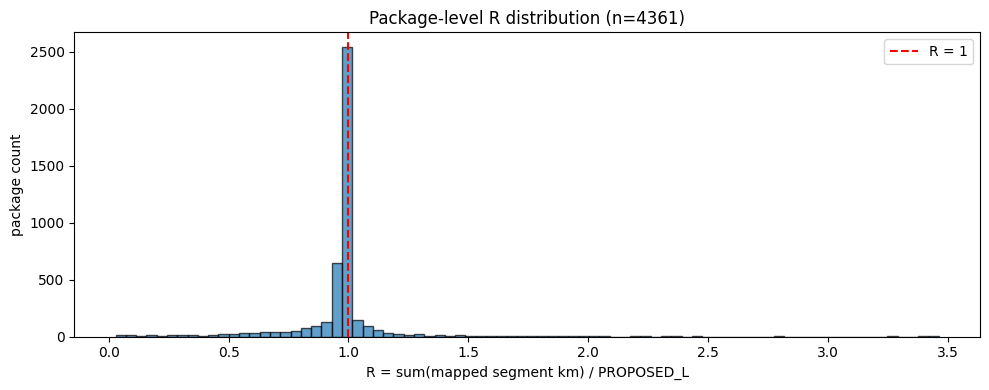


Saved ADD06_package_R_distribution.csv (per-package detail)


In [4]:
# ============================================================
# Cell 16 — Package-level R distribution
# ============================================================
# R = sum(mapped geometry length per MRL_ID) / PROPOSED_L
# Descriptive only. No anomaly thresholds applied. No model fitted.

import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from pathlib import Path
import os

if not os.path.exists("/content/drive/MyDrive"):
    from google.colab import drive
    drive.mount("/content/drive")

BASE_DIR = Path("/content/drive/MyDrive/mplad-dvc-storage")
assert BASE_DIR.exists(), f"Folder not found: {BASE_DIR}"

STATES = {
    "Bihar":          "Bihar_PMGSY-III",
    "Uttar Pradesh":  "UP_PMGSY-III",
    "Madhya Pradesh": "MP_PMGSY-III",
}

missing = [
    f"{stem}{ext}"
    for stem in STATES.values()
    for ext in (".shp", ".shx", ".dbf", ".prj")
    if not (BASE_DIR / f"{stem}{ext}").exists()
]
if missing:
    print(f"MISSING shapefile parts ({len(missing)}):")
    for m in missing:
        print(f"  {m}")
    print(f"\nActual contents of {BASE_DIR}:")
    for p in sorted(BASE_DIR.iterdir())[:40]:
        print(f"  {'DIR ' if p.is_dir() else 'FILE'}  {p.name}")
    raise FileNotFoundError("Shapefile parts missing — check BASE_DIR listing above.")

# -- Load and aggregate --
p_pieces = []
for state, stem in STATES.items():
    gdf = gpd.read_file(BASE_DIR / f"{stem}.shp").to_crs("EPSG:7755")
    gdf.columns = [c.upper() for c in gdf.columns]
    gdf = gdf.set_geometry("GEOMETRY")
    gdf["_state"]         = state
    gdf["_geom_len_km"]   = gdf.geometry.length / 1000.0
    gdf["PROPOSED_L_NUM"] = pd.to_numeric(gdf["PROPOSED_L"], errors="coerce")
    gdf["IMS_YEAR_NUM"]   = pd.to_numeric(gdf["IMS_YEAR"],   errors="coerce")
    p_pieces.append(gdf)

p = pd.concat(p_pieces, ignore_index=True)
p = p[p["PROPOSAL_T"].astype(str).str.upper() == "P"].copy()
print(f"P features (segment level): n={len(p)}")

pl_var = p.groupby("MRL_ID")["PROPOSED_L_NUM"].nunique()
n_multi_val = int((pl_var > 1).sum())
print(f"MRL_IDs with >1 distinct PROPOSED_L: {n_multi_val} "
      f"(expected 0 if truly a package-level attribute)")
if n_multi_val:
    print(f"  Examples: {pl_var[pl_var > 1].index.tolist()[:5]}")
    print("  (Each is itself a provenance anomaly — record, do not alter.)")

pkg = p.groupby("MRL_ID").agg(
    state       = ("_state",         "first"),
    n_states    = ("_state",         "nunique"),
    n_segments  = ("MRL_ID",         "size"),
    sum_geom_km = ("_geom_len_km",   "sum"),
    proposed_L  = ("PROPOSED_L_NUM", "first"),
    ims_year    = ("IMS_YEAR_NUM",   "first"),
).reset_index()

print(f"\nPackages: n={len(pkg)}")
print(f"  single-segment: {(pkg['n_segments'] == 1).sum()}")
print(f"  multi-segment:  {(pkg['n_segments'] > 1).sum()}")
print(f"  spanning multiple states: {(pkg['n_states'] > 1).sum()} (expected 0)")

pkg["R"] = np.where(
    pkg["proposed_L"] > 0,
    pkg["sum_geom_km"] / pkg["proposed_L"],
    np.nan,
)
n_undef = int(pkg["R"].isna().sum())
if n_undef:
    print(f"  WARNING: {n_undef} packages had proposed_L <= 0 (R undefined)")

r = pkg["R"].dropna()
print(f"\n=== R distribution (n={len(r)}) ===")
for q in [0.01, 0.05, 0.10, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99]:
    print(f"  p{q*100:02.0f} = {r.quantile(q):.4f}")
print(f"  mean = {r.mean():.4f}   min = {r.min():.4f}   max = {r.max():.4f}")

print("\n=== Tail counts (|R - 1| thresholds) ===")
for thresh in [0.05, 0.10, 0.20, 0.40]:
    lo = int((r < 1 - thresh).sum())
    hi = int((r > 1 + thresh).sum())
    print(f"  |R-1| > {thresh:>4.2f}:  {lo:>4d} below (<{1-thresh:.2f})  "
          f"{hi:>4d} above (>{1+thresh:.2f})")

print("\n=== By state ===")
for st in sorted(pkg["state"].dropna().unique()):
    sub = pkg[pkg["state"] == st]["R"].dropna()
    print(f"  {st:16s}  n={len(sub):>4d}  "
          f"median={sub.median():.3f}  "
          f"IQR={sub.quantile(0.75)-sub.quantile(0.25):.3f}  "
          f"p05={sub.quantile(0.05):.3f}  p95={sub.quantile(0.95):.3f}")

print("\n=== Single vs multi-segment packages ===")
for label, mask in [("single", pkg["n_segments"] == 1),
                    ("multi",  pkg["n_segments"] > 1)]:
    sub = pkg[mask]["R"].dropna()
    print(f"  {label:8s}  n={len(sub):>4d}  "
          f"median={sub.median():.3f}  "
          f"IQR={sub.quantile(0.75)-sub.quantile(0.25):.3f}")

fig, ax = plt.subplots(1, 1, figsize=(10, 4))
ax.hist(r, bins=80, edgecolor="black", alpha=0.7)
ax.axvline(1.0, color="red", linestyle="--", label="R = 1")
ax.set_xlabel("R = sum(mapped segment km) / PROPOSED_L")
ax.set_ylabel("package count")
ax.set_title(f"Package-level R distribution (n={len(r)})")
ax.legend()
plt.tight_layout()
plt.show()

out = BASE_DIR / "outputs"
pkg.to_csv(out / "ADD06_package_R_distribution.csv", index=False)
print(f"\nSaved ADD06_package_R_distribution.csv (per-package detail)")